# 02 - Classical ML: features, validation selection, results

Reads the caches from `featurize_fp.py`, `results/aml_params.json`, and the C4/summary files written by `metrics.py` / `aggregate.py`. Nothing is scored here by hand; test numbers only come from `summary.csv` / `headline.csv`.

In [1]:
import sys; sys.path.insert(0, "../src")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from tox.constants import CLEAN, TASKS, FIGURES, AML_PARAMS, SUMMARY, HEADLINE, ABLATIONS, AML_IMPORTANCE
from tox.featurize_fp import load_features, DESC_NAMES
from tox.splits import load

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight"})
df = pd.read_parquet(CLEAN)
fp, desc = load_features()
print(fp.shape, desc.shape)

(7709, 2048) (7709, 217)


## 1. Feature engineering

### Morgan fingerprint (radius 2, 2048 bits)

In [2]:
bits_per_mol = fp.sum(1)
never_set = int((fp.sum(0) == 0).sum())
print(f"mean bits set per molecule: {bits_per_mol.mean():.1f}  (density {bits_per_mol.mean() / fp.shape[1]:.4f})")
print(f"median {np.median(bits_per_mol):.0f}, min {bits_per_mol.min()}, max {bits_per_mol.max()}")
print(f"bits never set in the whole dataset: {never_set} / {fp.shape[1]}")
print(f"bits set in <1% of molecules: {int(((fp.mean(0) > 0) & (fp.mean(0) < 0.01)).sum())}")

mean bits set per molecule: 29.8  (density 0.0145)
median 26, min 1, max 160
bits never set in the whole dataset: 0 / 2048
bits set in <1% of molecules: 1487


### Bit collisions

The unfolded Morgan fingerprint gives every atom environment a 32-bit id; folding to 2048 bits takes `id % 2048`, so different environments can land on the same bit. Count how many distinct environments in Tox21 share a bit at 1024 vs 2048 bits.

In [3]:
sgen = rdFingerprintGenerator.GetMorganGenerator(radius=2)
env_ids = set()
for s in df.smiles:
    env_ids.update(sgen.GetSparseCountFingerprint(Chem.MolFromSmiles(s)).GetNonzeroElements())
env_ids = np.array(sorted(env_ids), dtype=np.int64)
print("distinct radius<=2 environments in the dataset:", len(env_ids))
for size in (1024, 2048):
    per_bit = np.bincount(env_ids % size, minlength=size)
    print(f"{size} bits: {int((per_bit > 1).sum())} bits hold >1 environment, "
          f"mean {per_bit[per_bit > 0].mean():.1f} environments per used bit")

distinct radius<=2 environments in the dataset: 26749
1024 bits: 1024 bits hold >1 environment, mean 26.1 environments per used bit
2048 bits: 2048 bits hold >1 environment, mean 13.1 environments per used bit


There are ~13x more distinct environments than bits, so *every* bit is shared by several substructures (26 per bit at 1024, 13 at 2048). So one XGBoost bit importance is not one substructure - Phase 2 interpretability has to map bits back with `bitInfo` per molecule.

### Descriptors

In [4]:
d = np.where(np.isinf(desc), np.nan, desc)
nan_cols = [DESC_NAMES[i] for i in np.where(np.isnan(d).any(0))[0]]
const_cols = [DESC_NAMES[i] for i in np.where(np.nanstd(d, 0) == 0)[0]]
print(f"{len(DESC_NAMES)} rdkit descriptors")
print(f"columns with NaN/inf ({len(nan_cols)}):", nan_cols)
print(f"rows affected: {int(np.isnan(d).any(1).sum())}  (100 of them contain a metal/metalloid - organotin, As, Hg, Cr... - where Gasteiger charges fail)")
print(f"constant over the full dataset ({len(const_cols)}):", const_cols)

217 rdkit descriptors
columns with NaN/inf (12): ['MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW']
rows affected: 107  (100 of them contain a metal/metalloid - organotin, As, Hg, Cr... - where Gasteiger charges fail)
constant over the full dataset (3): ['SMR_VSA8', 'SlogP_VSA9', 'fr_diazo']


In [5]:
n_labelled = df[TASKS].notna().sum(1)
hac = desc[:, DESC_NAMES.index("HeavyAtomCount")]
for name, x in [("bits set", bits_per_mol), ("heavy atoms", hac)]:
    r, p = spearmanr(x, n_labelled)
    print(f"spearman({name}, #labelled endpoints) = {r:.3f}  (p={p:.1e})")

spearman(bits set, #labelled endpoints) = -0.354  (p=8.6e-227)
spearman(heavy atoms, #labelled endpoints) = -0.390  (p=1.3e-278)


/var/folders/b7/m_nr71s115ld7m85whyltltm0000gn/T/ipykernel_79009/3783565226.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  n_labelled = df[TASKS].notna().sum(1)


Label availability is **not** independent of structure: bigger molecules are labelled on fewer endpoints (Spearman about -0.39). So labels are not missing completely at random, and each endpoint's training set slightly under-represents large molecules. Masking is still the right choice (imputing 0 would be worse), but it's a limitation to state.

## 2. Validation - model selection

Each endpoint picks its hyper-parameters on **val PR-AUC**. Model choice below also uses val only; test is not looked at until section 3.

In [6]:
params = json.loads(AML_PARAMS.read_text())
rows = []
for model, runs in params.items():
    for run, tasks in runs.items():
        split = run.split("__")[0]
        fam = "scaffold_det" if split == "scaffold_det" else split.rsplit("_", 1)[0]
        for t, info in tasks.items():
            rows.append(dict(model=model, split=fam, run=run, task=t, val_pr_auc=info["val_pr_auc"], **info["params"]))
val = pd.DataFrame(rows)
val_tab = val.groupby(["model", "split"]).val_pr_auc.mean().unstack().round(3)
print(val_tab.to_string())
best = {fam: val_tab[fam].idxmax() for fam in val_tab.columns}
print("\nselected on val:", best)

split       random  scaffold  scaffold_det
model                                     
lr_fp        0.432     0.408         0.352
lr_fpdesc    0.453     0.416         0.336
rf_fp        0.472     0.435         0.406
rf_fpdesc    0.522     0.480         0.451
xgb_fp       0.459     0.434         0.375
xgb_fpdesc   0.542     0.490         0.444

selected on val: {'random': 'xgb_fpdesc', 'scaffold': 'xgb_fpdesc', 'scaffold_det': 'rf_fpdesc'}


best config per endpoint on val (scaffold_det):
task
NR-AR                 rf_fp
NR-AR-LBD         rf_fpdesc
NR-AhR            rf_fpdesc
NR-Aromatase      rf_fpdesc
NR-ER             rf_fpdesc
NR-ER-LBD             rf_fp
NR-PPAR-gamma         rf_fp
SR-ARE           xgb_fpdesc
SR-ATAD5         xgb_fpdesc
SR-HSE            rf_fpdesc
SR-MMP           xgb_fpdesc
SR-p53            rf_fpdesc

fp vs fp+desc, per algorithm: #endpoints where fp+desc has higher val PR-AUC
  lr: 5/12
  rf: 8/12
  xgb: 12/12


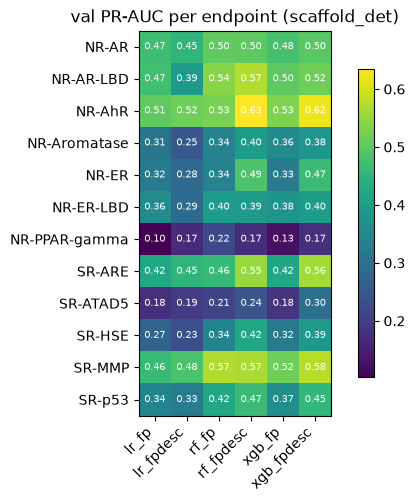

In [7]:
per_task = val[val.split == "scaffold_det"].groupby(["task", "model"]).val_pr_auc.mean().unstack()[val_tab.index]
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(per_task, cmap="viridis")
ax.set_xticks(range(per_task.shape[1]), per_task.columns, rotation=45, ha="right"); ax.set_yticks(range(12), per_task.index)
for i in range(per_task.shape[0]):
    for j in range(per_task.shape[1]):
        ax.text(j, i, f"{per_task.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("val PR-AUC per endpoint (scaffold_det)")
fig.savefig(FIGURES / "aml_val_prauc_heatmap.png")
wins = per_task.idxmax(1)
print("best config per endpoint on val (scaffold_det):"); print(wins.to_string())
print("\nfp vs fp+desc, per algorithm: #endpoints where fp+desc has higher val PR-AUC")
for a in ("lr", "rf", "xgb"):
    print(f"  {a}: {int((per_task[a + '_fpdesc'] > per_task[a + '_fp']).sum())}/12")

In [8]:
print("chosen hyper-parameters (count over all endpoints x runs):")
for m, col in [("lr", "C"), ("rf", "min_samples_leaf"), ("xgb", "max_depth")]:
    print(f"  {m}: {val[val.model.str.startswith(m)][col].value_counts().to_dict()}")

chosen hyper-parameters (count over all endpoints x runs):
  lr: {0.1: 102, 0.01: 84, 1.0: 30}
  rf: {1.0: 125, 3.0: 91}
  xgb: {6.0: 141, 4.0: 75}


Val picks `rf_fpdesc` on `scaffold_det` and `xgb_fpdesc` on the other two families. Per endpoint, RF wins most NR tasks and XGB wins SR-ARE/SR-ATAD5/SR-MMP. Adding descriptors helps XGB on every endpoint and RF on 8/12, but LR only on 5/12 - a linear model can't use most of the extra 200 dense features well.

## 3. Test results

From `results/headline.csv` (12-task mean per run, then mean ± std over the 3 runs). PR-AUC baseline = positive rate, shown in the last column.

In [9]:
head = pd.read_csv(HEADLINE)
tab = head.pivot(index="model", columns="split", values=["roc_auc_mean", "roc_auc_std", "pr_auc_mean", "pr_auc_std"])
show = pd.DataFrame({f"{m} {s}": tab[(f"{m}_mean", s)].map("{:.3f}".format) + " ± " + tab[(f"{m}_std", s)].map("{:.3f}".format)
                     for m in ("roc_auc", "pr_auc") for s in ("scaffold_det", "scaffold", "random")})
print(show.to_string())
print("\nmean test positive rate:", head.groupby("split").pos_rate.first().round(3).to_dict())

           roc_auc scaffold_det roc_auc scaffold roc_auc random pr_auc scaffold_det pr_auc scaffold  pr_auc random
model                                                                                                             
lr_fp             0.715 ± 0.000    0.775 ± 0.036  0.801 ± 0.013       0.319 ± 0.000   0.395 ± 0.051  0.435 ± 0.038
lr_fpdesc         0.722 ± 0.000    0.788 ± 0.039  0.827 ± 0.010       0.299 ± 0.000   0.367 ± 0.068  0.463 ± 0.029
rf_fp             0.732 ± 0.001    0.803 ± 0.019  0.833 ± 0.009       0.366 ± 0.001   0.442 ± 0.043  0.484 ± 0.019
rf_fpdesc         0.782 ± 0.003    0.839 ± 0.024  0.862 ± 0.002       0.406 ± 0.002   0.481 ± 0.043  0.531 ± 0.016
xgb_fp            0.696 ± 0.003    0.767 ± 0.045  0.801 ± 0.012       0.306 ± 0.006   0.389 ± 0.047  0.435 ± 0.024
xgb_fpdesc        0.761 ± 0.008    0.813 ± 0.032  0.855 ± 0.007       0.391 ± 0.008   0.446 ± 0.057  0.520 ± 0.020

mean test positive rate: {'random': 0.077, 'scaffold': 0.103, 'scaffold_det': 0

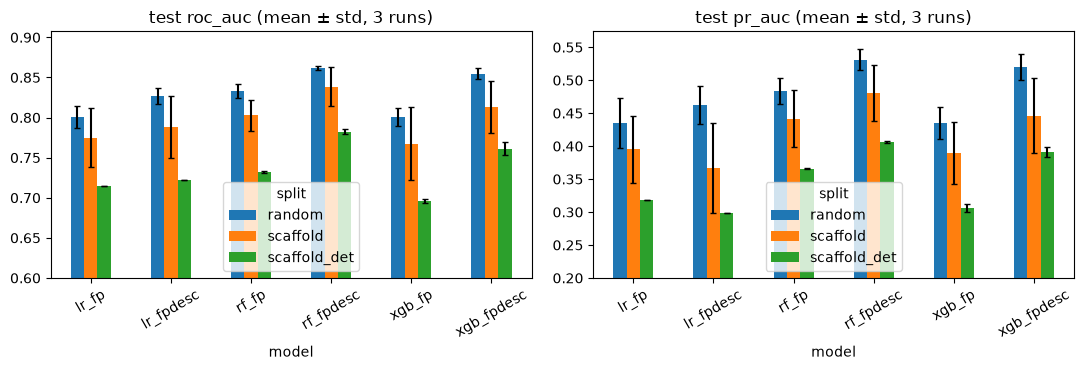

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = ["lr_fp", "lr_fpdesc", "rf_fp", "rf_fpdesc", "xgb_fp", "xgb_fpdesc"]
for k, metric in enumerate(["roc_auc", "pr_auc"]):
    m = head.pivot(index="model", columns="split", values=f"{metric}_mean").loc[order, ["random", "scaffold", "scaffold_det"]]
    e = head.pivot(index="model", columns="split", values=f"{metric}_std").loc[order, ["random", "scaffold", "scaffold_det"]]
    m.plot.bar(yerr=e, ax=ax[k], capsize=2); ax[k].set_title(f"test {metric} (mean ± std, 3 runs)")
    ax[k].set_ylim(0.2 if metric == "pr_auc" else 0.6, None); ax[k].tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIGURES / "aml_test_split_gap.png")

In [11]:
summ = pd.read_csv(SUMMARY)
best_model = best["scaffold_det"]
t = summ[(summ.model == best_model)].pivot(index="task", columns="split", values=["roc_auc_mean", "pr_auc_mean", "pos_rate"]).loc[TASKS]
print(f"per-endpoint test results for the val-selected model ({best_model}):")
print(t.round(3).to_string())

per-endpoint test results for the val-selected model (rf_fpdesc):
              roc_auc_mean                       pr_auc_mean                       pos_rate                      
split               random scaffold scaffold_det      random scaffold scaffold_det   random scaffold scaffold_det
task                                                                                                             
NR-AR                0.765    0.801        0.756       0.492    0.521        0.449    0.043    0.058        0.045
NR-AR-LBD            0.889    0.878        0.856       0.637    0.559        0.456    0.035    0.057        0.033
NR-AhR               0.908    0.861        0.846       0.666    0.592        0.613    0.123    0.170        0.152
NR-Aromatase         0.874    0.802        0.746       0.433    0.416        0.374    0.048    0.088        0.086
NR-ER                0.741    0.794        0.692       0.479    0.526        0.406    0.120    0.142        0.147
NR-ER-LBD            0

- Every model loses performance going from random to scaffold splits; ROC-AUC drops by about 0.08-0.11 on `scaffold_det`. That's the generalization penalty the project is about.
- Compare PR-AUC only within a column: the test positive rate is 0.103 on the scaffold splits vs 0.077 on random, which raises the PR-AUC baseline.
- `rf_fpdesc` is the best model on test for all three families. On `random`/`scaffold` val had picked `xgb_fpdesc` (a close second). We report the val-selected model anyway - picking the winner on test would be selection on test.
- Seed spread on the balanced scaffold splits (std 0.02-0.05) is much larger than on `scaffold_det` (< 0.01), because there the split itself changes, not just the model seed. One deterministic scaffold split hides that variance.

## 4. Fingerprint ablation (XGBoost, scaffold_det, 3 seeds)

In [12]:
rows = []
for f in sorted((ABLATIONS / "metrics").glob("*.csv")):
    name, _, seed = f.stem.split("__")
    d = pd.read_csv(f)
    rows.append(dict(config=name, seed=seed, roc_auc=d.roc_auc.mean(), pr_auc=d.pr_auc.mean()))
abl = pd.DataFrame(rows).groupby("config").agg(roc_auc=("roc_auc", "mean"), roc_std=("roc_auc", "std"),
                                               pr_auc=("pr_auc", "mean"), pr_std=("pr_auc", "std"))
print(abl.round(3).sort_values("pr_auc", ascending=False).to_string())

                roc_auc  roc_std  pr_auc  pr_std
config                                          
xgb_desc          0.761    0.001   0.402   0.003
xgb_fp-r1-1024    0.704    0.003   0.323   0.012
xgb_fp-r2-2048    0.696    0.003   0.306   0.006
xgb_fp-r3-2048    0.695    0.008   0.304   0.005
xgb_fp-r1-2048    0.693    0.006   0.303   0.006
xgb_fp-r3-1024    0.683    0.007   0.300   0.010
xgb_fp-r2-1024    0.688    0.002   0.297   0.007


Radius and length barely matter on `scaffold_det`: all six fingerprints land in ROC-AUC 0.683-0.704 with no consistent trend in radius or length (r1-1024 is marginally best, but a 0.02 spread is not worth reading into). Descriptors alone (0.761) beat every fingerprint and equal FP+desc XGBoost (0.761), so on unseen scaffolds the whole-molecule properties carry most of the signal and the substructure bits add little.

## 5. What XGBoost uses (gain importance, scaffold_det seed 0)

In [13]:
imp = pd.read_csv(AML_IMPORTANCE / "xgb_fpdesc__scaffold_det.csv")
imp["kind"] = np.where(imp.feature.str.startswith("bit"), "fingerprint bit", "descriptor")
share = imp.groupby(["task", "kind"]).gain.sum().unstack().fillna(0)
print("share of total gain from descriptors, per endpoint:")
print((share["descriptor"] / share.sum(1)).round(2).to_string())
for t in ["SR-MMP", "NR-AhR"]:
    print(f"\ntop 10 features for {t}:", imp[imp.task == t].head(10).feature.tolist())

share of total gain from descriptors, per endpoint:
task
NR-AR            0.34
NR-AR-LBD        0.47
NR-AhR           0.51
NR-Aromatase     0.36
NR-ER            0.36
NR-ER-LBD        0.43
NR-PPAR-gamma    0.55
SR-ARE           0.35
SR-ATAD5         0.53
SR-HSE           0.43
SR-MMP           0.39
SR-p53           0.57

top 10 features for SR-MMP: ['fr_benzene', 'fr_phenol', 'bit1778', 'bit1380', 'bit1348', 'bit1873', 'BCUT2D_LOGPHI', 'bit1602', 'fr_Ar_OH', 'fr_phenol_noOrthoHbond']

top 10 features for NR-AhR: ['fr_benzene', 'NumAromaticCarbocycles', 'NumAromaticRings', 'FractionCSP3', 'bit1380', 'bit1203', 'fr_ArN', 'SlogP_VSA10', 'RingCount', 'SlogP_VSA11']


/var/folders/b7/m_nr71s115ld7m85whyltltm0000gn/T/ipykernel_79009/1783231558.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print((share["descriptor"] / share.sum(1)).round(2).to_string())


Descriptors are only 217 of 2265 columns but get 34-57% of the total gain. The top features make chemical sense: aromatic ring counts drive NR-AhR (the aryl hydrocarbon receptor binds planar aromatics), and phenol counts show up for SR-MMP (mitochondrial membrane potential disruptors include many phenols).